# Entrega 2: Preparación y Análisis de los Datos

**Dataset:** `miguel-mxrxra04/multimodal-climate-change-2008-2026` (Hugging Face, Entrega 1): una fila por semana (2008-2026) con la entradilla del artículo de Wikipedia *Climate change* y varias series numéricas (CO₂, Brent, temperatura, CH₄, N₂O, ONI).

**Objetivo (enunciado):** preparar el dataset, explorarlo y generar indicadores básicos que permitan formular una hipótesis.

| # | Apartado del enunciado | Estado |
|---|---|---|
| 1 | Procesamiento y limpieza (`data_cleaning.md`, `data/processed/`) | ✅ |
| 2.1 | Indicador obligatorio: volumen temporal | ✅ |
| 2.2 | Indicador obligatorio: sentimiento medio agregado (modelo en español) | ✅ |
| 2.3 | Indicador obligatorio: distribución de tópicos | ✅ |
| 2.4 | Tabla conjunta de los indicadores obligatorios | ✅ |
| 3 | Indicador opcional (solo 1): palabras clave | ✅ |
| 4 | Hipótesis (1): informes del IPCC y términos en auge | ✅ |
| 5 | Entregables (`motivation.md`) | ✅ |

## 0. Configuración

In [160]:
!pip install -q datasets pandas pyarrow mwparserfromhell matplotlib tqdm

import os
import re

import matplotlib.pyplot as plt
import mwparserfromhell
import pandas as pd

# 1. Procesamiento y limpieza

## 1.1. Carga del dataset publicado en Hugging Face

In [161]:
from datasets import load_dataset

dataset = load_dataset(
    "miguel-mxrxra04/multimodal-climate-change-2008-2026",
    split="train"
)

df = dataset.to_pandas()

print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (978, 16)


,id,timestamp,text,co2_ppm,brent_price,temp_anomaly_c,ch4_ppb,n2o_ppb,oni_anomaly,rev_id,rev_timestamp,rev_size,source_text,source_metrics,domain,media_volume_norm
0,42d8fc2f-ecbb-5f89-891b-2fede01190d1,2008-01-06,{{pp-semi-protected|small=yes}}{{featured arti...,384.67,94.389999,0.5,1788.04,321.062,-1.72,182620278,2008-01-06T23:02:37Z,91379,Wikipedia (EN) - MediaWiki Revision API,NOAA GML / NOAA CPC / NASA GISTEMP / Yahoo Fin...,Climate Change Multimodal Time Series,0.000000
1,5c69d4fd-ec1d-5407-8d1d-97551b076b2c,2008-01-13,{{pp-semi-protected|small=yes}}{{featured arti...,386.05,92.919998,0.5,1788.04,321.062,-1.72,184060786,2008-01-13T16:33:04Z,91515,Wikipedia (EN) - MediaWiki Revision API,NOAA GML / NOAA CPC / NASA GISTEMP / Yahoo Fin...,Climate Change Multimodal Time Series,0.003495
2,25d3a316-5653-58a3-b5d8-017eafcafec0,2008-01-20,{{pp-semi-protected|small=yes}}{{featured arti...,386.25,87.699997,0.5,1788.04,321.062,-1.72,185714833,2008-01-20T21:35:34Z,92739,Wikipedia (EN) - MediaWiki Revision API,NOAA GML / NOAA CPC / NASA GISTEMP / Yahoo Fin...,Climate Change Multimodal Time Series,0.002065
3,2d5f03bd-f225-599b-b394-bc2d03c21c68,2008-01-27,{{pp-semi-protected|small=yes}}{{featured arti...,387.02,91.379997,0.5,1788.04,321.062,-1.72,187293384,2008-01-27T18:32:45Z,92412,Wikipedia (EN) - MediaWiki Revision API,NOAA GML / NOAA CPC / NASA GISTEMP / Yahoo Fin...,Climate Change Multimodal Time Series,0.000000
4,e44029d9-e0e2-5fb6-8fa4-77b7aed7e6c3,2008-02-03,{{pp-semi-protected|small=yes}}{{featured arti...,386.25,90.400002,0.3,1786.69,321.167,-1.76,188895354,2008-02-03T22:14:55Z,93638,Wikipedia (EN) - MediaWiki Revision API,NOAA GML / NOAA CPC / NASA GISTEMP / Yahoo Fin...,Climate Change Multimodal Time Series,0.018907


## 1.2. Exploración inicial de la calidad

Antes de limpiar hay que saber qué tenemos: si la serie es regular y cuánto texto se repite. Como el artículo cambia poco de una semana a otra, esperamos muchos textos repetidos; eso condiciona la limpieza (duplicados) y todo el análisis posterior.

In [162]:
fechas = pd.to_datetime(df["timestamp"]).sort_values()
print("Periodo:", fechas.min().date(), "->", fechas.max().date())
print("Intervalos entre observaciones:\n", fechas.diff().value_counts())

n_unicos = df["text"].nunique()
print(f"Observaciones: {len(df)} | textos únicos: {n_unicos} "
      f"| repetidos: {len(df) - n_unicos} ({(len(df) - n_unicos) / len(df):.1%})")

Periodo: 2008-01-06 -> 2026-09-27
Intervalos entre observaciones:
 timestamp
7 days    977
Name: count, dtype: int64
Observaciones: 978 | textos únicos: 568 | repetidos: 410 (41.9%)


## 1.3. Revisión de las columnas numéricas

La hipótesis acabará cruzando los indicadores con las series numéricas (CO₂, temperatura, ONI, Brent...), así que se revisan ahora: fechas ordenadas y sin duplicados, nulos y, sobre todo, **cada cuánto cambia realmente cada variable**. Varias series son mensuales y el dataset las repite en las semanas de ese mes; si el porcentaje de semanas con el mismo valor es muy alto, esa serie tiene mucha menos información independiente de la que sugieren las 978 filas (conviene agregar por mes).

In [163]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
print("Fechas duplicadas:", df["timestamp"].duplicated().sum(), "| serie ordenada:", df["timestamp"].is_monotonic_increasing)

COLS_NUM = [c for c in ["co2_ppm", "brent_price", "temp_anomaly_c", "ch4_ppb", "n2o_ppb",
                        "oni_anomaly", "media_volume_norm", "rev_size"] if c in df.columns]
print("\nNulos por columna:\n", df[COLS_NUM].isna().sum())

repetido = df[COLS_NUM].apply(lambda s: s.eq(s.shift()).mean()).round(2)
print("\nFracción de semanas con el mismo valor que la semana anterior:")
print(repetido.sort_values(ascending=False))

Fechas duplicadas: 0 | serie ordenada: True

Nulos por columna:
 co2_ppm              0
brent_price          0
temp_anomaly_c       0
ch4_ppb              0
n2o_ppb              0
oni_anomaly          0
media_volume_norm    0
rev_size             0
dtype: int64

Fracción de semanas con el mismo valor que la semana anterior:
temp_anomaly_c       0.78
ch4_ppb              0.77
oni_anomaly          0.77
n2o_ppb              0.77
media_volume_norm    0.24
rev_size             0.10
co2_ppm              0.01
brent_price          0.01
dtype: float64


## 1.4. Limpieza del texto (WikiText → texto plano)

El campo `text` es WikiText crudo (plantillas `{{...}}`, enlaces `[[...]]`, referencias, comentarios HTML). Usamos `mwparserfromhell` para convertirlo en texto plano.

**Decisión importante:** `strip_code()` borra *todas* las plantillas, incluidas las que llevan contenido visible, como `{{convert|1.1|C}}` (→ "1.1 °C") o `{{CO2}}` (→ "CO2"). Si no se tratan antes, el texto queda con huecos ("la temperatura subió en ." o "metano ()") y eso contamina el sentimiento y los tópicos. Por eso primero se sustituyen las plantillas con contenido por su texto visible y después se elimina el resto.

In [164]:
UNIDADES = {"C": "°C", "F": "°F", "km2": "km²", "m2": "m²"}
CONECTORES = {"to", "-", "–", "and", "or", "±"}


def plantilla_a_texto(t):
    """Texto visible de una plantilla con contenido; None si hay que descartarla."""
    nombre = str(t.name).strip().lower()
    args = [str(p.value).strip() for p in t.params if not p.showkey]
    if nombre in ("convert", "cvt") and args:
        if len(args) >= 4 and args[1] in CONECTORES:  # rangos: {{convert|1.5|to|2|C}}
            valor, unidad = f"{args[0]} {args[1]} {args[2]}", args[3]
        else:
            valor, unidad = args[0], (args[1] if len(args) > 1 else "")
        return f"{valor} {UNIDADES.get(unidad, unidad)}".strip()
    if nombre in ("co2", "ch4", "n2o"):
        return nombre.upper()
    if nombre in ("nowrap", "em", "val") and args:
        return args[0]
    if nombre in ("chem", "chem2") and args:
        return "".join(args)
    if nombre == "nbsp":
        return " "
    return None

def limpiar_texto(texto):
    if pd.isna(texto):
        return ""

    # 1. Comentarios HTML
    texto = re.sub(r"<!--.*?-->", " ", str(texto), flags=re.DOTALL)
    wiki = mwparserfromhell.parse(texto)

    # 2. Plantillas con contenido -> su texto (las anidadas primero, de ahí el reversed)
    for t in reversed(wiki.filter_templates(recursive=True)):
        visible = plantilla_a_texto(t)
        if visible is not None and wiki.contains(t):
            wiki.replace(t, visible)

    # 3. Imágenes y sus descripciones
    for enlace in list(wiki.filter_wikilinks(recursive=True)):
        if str(enlace.title).strip().lower().startswith(("image:", "file:", "archivo:", "imagen:")):
            wiki.remove(enlace, recursive=True)

    # 4. Resto de marcas (referencias, plantillas, negritas...) y normalización de espacios
    texto = re.sub(r"\s+", " ", wiki.strip_code()).strip()
    return re.sub(r"\s+([.,;:])", r"\1", texto)  # huecos que dejan las referencias eliminadas

In [165]:
df_clean = df.copy()
df_clean["text_clean"] = df_clean["text"].apply(limpiar_texto)

print(df_clean["text_clean"].iloc[-1][:600])

Present-day climate change includes both global warming—the ongoing increase in global average temperature—and its wider effects on Earth's climate system. In a broader sense, climate change also includes previous long-term changes to Earth's climate. The modern-day rise in global temperatures is driven by human activities, especially fossil fuel (coal, oil and natural gas) burning since the Industrial Revolution.: "For the 2016–2025 decade average, observed warming relative to 1850–1900 was 1.26 [1.13 to 1.36] °C, of which 1.24 [1.0 to 1.5] °C was human-induced." Fossil fuel use, deforestatio


## 1.5. Normalización del texto

El enunciado pide normalizar el texto. Aquí solo se hacen las normalizaciones **comunes a todos los indicadores**: unificar la codificación Unicode, comillas y guiones, quitar un resto típico de las citas en bloque de Wikipedia (`...Revolution.: "For...`) y separar frases que quedan pegadas al borrar las referencias (`warming.The U.S....`).

**Decisión:** no se pasa a minúsculas, ni se quitan stopwords ni se lematiza aquí, porque cada indicador lo necesita distinto (LDA sí; un modelo de sentimiento o de embeddings funciona mejor con el texto natural). Eso se hará dentro de cada indicador.

In [166]:
import unicodedata


def normalizar_texto(texto):
    texto = unicodedata.normalize("NFKC", texto)                       # codificación unificada
    texto = texto.replace("“", '"').replace("”", '"').replace("‘", "'").replace("’", "'")
    texto = texto.replace("—", " - ").replace("–", "-")                # guiones
    texto = re.sub(r"([.!?]):\s", r"\1 ", texto)                       # '.: "' de las citas en bloque
    texto = re.sub(r"([a-z]{2,}[.!?])([A-Z])", r"\1 \2", texto)       # 'warming.The' -> 'warming. The' (referencias borradas)
    return re.sub(r"\s+", " ", texto).strip()


df_clean["text_clean"] = df_clean["text_clean"].apply(normalizar_texto)
print(df_clean["text_clean"].iloc[-1][:500])

Present-day climate change includes both global warming - the ongoing increase in global average temperature - and its wider effects on Earth's climate system. In a broader sense, climate change also includes previous long-term changes to Earth's climate. The modern-day rise in global temperatures is driven by human activities, especially fossil fuel (coal, oil and natural gas) burning since the Industrial Revolution. "For the 2016-2025 decade average, observed warming relative to 1850-1900 was 


## 1.6. Verificación de la limpieza

Comprobamos que no quedan textos vacíos, ni restos de marcas wiki, ni huecos del tipo `()` (el síntoma de plantillas con contenido borradas).

In [167]:
print("Observaciones:", len(df_clean))
print("Textos vacíos:", (df_clean["text_clean"] == "").sum())
print("Restos de marcas wiki:", df_clean["text_clean"].str.contains(r"\{\{|\[\[|<ref\b|thumb\|", regex=True).sum())
print("Paréntesis vacíos '()':", df_clean["text_clean"].str.contains(r"\(\s*\)").sum())
print("Textos únicos tras limpiar:", df_clean["text_clean"].nunique())

Observaciones: 978
Textos vacíos: 0
Restos de marcas wiki: 0
Paréntesis vacíos '()': 0
Textos únicos tras limpiar: 376


## 1.7. Marcar los textos nuevos y añadir columnas temporales

Como ~60 % de las semanas repite el texto de la anterior, esas semanas **no son observaciones independientes** de sentimiento o tópicos. Se añaden:
- `text_id`: identificador de cada texto limpio distinto (por orden de aparición).
- `texto_nuevo`: `True` si el texto cambió respecto a la semana anterior.
- `anio` y `mes`: para agregar cualquier indicador por intervalo temporal.

In [168]:
df_clean = df_clean.sort_values("timestamp").reset_index(drop=True)

df_clean["text_id"] = pd.factorize(df_clean["text_clean"])[0]
df_clean["texto_nuevo"] = df_clean["text_id"].ne(df_clean["text_id"].shift(1))
df_clean["anio"] = df_clean["timestamp"].dt.year
df_clean["mes"] = df_clean["timestamp"].dt.to_period("M").astype(str)

print("Semanas con texto nuevo:", df_clean["texto_nuevo"].sum(), "de", len(df_clean))
display(df_clean[["timestamp", "text_id", "texto_nuevo", "anio", "mes"]].head())

Semanas con texto nuevo: 380 de 978


,timestamp,text_id,texto_nuevo,anio,mes
0,2008-01-06,0,True,2008,2008-01
1,2008-01-13,1,True,2008,2008-01
2,2008-01-20,2,True,2008,2008-01
3,2008-01-27,2,False,2008,2008-01
4,2008-02-03,3,True,2008,2008-02


## 1.8. Eliminación de duplicados y guardado

El enunciado pide eliminar duplicados, pero los indicadores temporales necesitan la serie semanal completa. **Decisión:** se guardan las dos versiones: la serie semanal completa (`dataset_clean`, para agregar por intervalo) y los textos únicos (`textos_unicos`, para los pasos caros como traducir, calcular sentimiento y entrenar tópicos). Después se vuelve a la serie semanal uniendo por `text_id`. Ambas versiones se guardan en `data/processed/`.

In [169]:
df_unique = df_clean.drop_duplicates("text_id", keep="first").reset_index(drop=True)

print("Observaciones que repiten un texto anterior:", df_clean["text_clean"].duplicated().sum())
print("Textos únicos:", len(df_unique))

os.makedirs("data/processed", exist_ok=True)

df_clean.to_parquet("data/processed/dataset_clean.parquet", index=False)
df_unique.to_parquet("data/processed/textos_unicos.parquet", index=False)
print("Guardado en data/processed/")

Observaciones que repiten un texto anterior: 602
Textos únicos: 376
Guardado en data/processed/


## 1.9. Documentar la limpieza en `data_cleaning.md`

In [170]:
lista_repetidos = chr(10).join(f"  - `{k}`: {v:.0%}" for k, v in repetido.items())
n_nuevo = int(df_clean["texto_nuevo"].sum())

contenido = f"""# Data Cleaning — Entrega 2

## 1. Dataset original

- Fuente: Hugging Face, `miguel-mxrxra04/multimodal-climate-change-2008-2026`
- Observaciones: {len(df)} (frecuencia semanal); texto de la entradilla de Wikipedia en inglés

## 2. Revisión de las columnas numéricas

- Fechas ordenadas y sin duplicados; nulos en columnas numéricas: {int(df[COLS_NUM].isna().sum().sum())}.
- Las series mensuales (temperatura, CH4, N2O, ONI) se repiten en las semanas de cada mes.
  Porcentaje de semanas con el mismo valor que la semana anterior:
{lista_repetidos}
- `media_volume_norm` (cobertura mediática de GDELT) es un proxy, con valores casi siempre cercanos a 0.

## 3. Transformaciones aplicadas al texto

1. Eliminación de comentarios HTML.
2. Plantillas con contenido (`convert`, `CO2`, `CH4`, `N2O`, `nowrap`, `chem`...) sustituidas por su texto visible, para no dejar huecos al borrar plantillas.
3. Eliminación de imágenes, referencias y resto de plantillas con `mwparserfromhell`.
4. Normalización: Unicode NFKC, comillas y guiones unificados, restos de citas en bloque y espacios (columna `text_clean`).
   No se pasa a minúsculas ni se eliminan stopwords: se hace dentro de cada indicador.
5. Columnas añadidas: `text_id`, `texto_nuevo`, `anio`, `mes`.
6. Eliminación de duplicados: {df_clean["text_clean"].duplicated().sum()} observaciones repiten un texto anterior.
   Se guardan dos versiones: la serie semanal completa y los textos únicos.

## 4. Resultados

- Observaciones: {len(df_clean)} (la ficha de Hugging Face indica 977 registros, el dataset descargado tiene {len(df)})
- Textos únicos: {len(df_unique)}
- Semanas con texto distinto al de la semana anterior: {n_nuevo}. Es mayor que el número de textos únicos
  porque en {n_nuevo - len(df_unique)} semanas el artículo vuelve a un texto ya visto (p. ej. reversiones de ediciones).
- Textos vacíos: {(df_clean["text_clean"] == "").sum()}

## 5. Limitaciones

- Un único artículo de Wikipedia y solo su entradilla, con estilo enciclopédico (sentimiento poco expresivo).
- Elevada repetición: el texto cambia poco de una semana a otra.
- Texto original en inglés (se traduce al español para el sentimiento).

## 6. Archivos generados

- `data/processed/dataset_clean.parquet`
- `data/processed/textos_unicos.parquet`
"""

with open("data_cleaning.md", "w", encoding="utf-8") as f:
    f.write(contenido)
print("Creado data_cleaning.md")

Creado data_cleaning.md


# 2. Indicadores obligatorios (mínimos)

Los tres indicadores se calculan sobre **la misma base temporal** para poder compararlos y cruzarlos después en la hipótesis: **semana** como unidad de cálculo y **mes** como intervalo de agregación (varias series numéricas del dataset son mensuales).

| Indicador | Qué mide | Cálculo | Agregación mensual | Archivos en `data/processed/` |
|---|---|---|---|---|
| 2.1 Volumen | Revisiones del artículo de Wikipedia | Conteo por semana (API de Wikipedia) | Media por semana y total | `volumen_semanal.csv`, `volumen_mensual.csv` |
| 2.2 Sentimiento | Tono del texto: P(pos) − P(neg) | Por texto único → se lleva a cada semana | Media | `sentimiento_semanal.csv`, `sentimiento_mensual.csv` |
| 2.3 Tópicos | Proporción de cada tópico (LDA) | Por texto único → se lleva a cada semana | Media | `topicos_semanal.csv`, `topicos_mensual.csv` |

Al final (2.4) se juntan los tres en una sola tabla mensual, `indicadores_mensual.csv`, junto con las series numéricas. Esa tabla es la base de la hipótesis.

## 2.1. Volumen temporal de publicaciones

El dataset tiene una sola revisión del artículo por semana, no publicaciones individuales. **Decisión:** definimos el volumen como el **número de revisiones (ediciones) del artículo por semana**, que sí se puede obtener completo de la API de Wikipedia.

### 2.1.1. Descargar el historial completo de revisiones

In [171]:
# Parámetros para recuperar el historial completo (de más antiguo a más reciente)
# (en el cuaderno original `params` y `revisiones` no estaban definidos en esta celda)
url = "https://en.wikipedia.org/w/api.php"
params = {
    "action": "query",
    "prop": "revisions",
    "titles": "Climate change",
    "rvprop": "timestamp|ids",
    "rvlimit": "max",
    "rvdir": "newer",
    "rvstart": "2007-12-31T00:00:00Z",
    "format": "json",
}
revisiones = []

import requests
import pandas as pd
import time

# Continuar desde la última consulta realizada
params["maxlag"] = 5

headers = {
    "User-Agent": (
        "UPMClimateResearch/1.0 "
        "(https://github.com/daaniii22/complex-data-analysis)"
    )
}

intentos = 0
completado = False

while True:
    respuesta = requests.get(
        url,
        params=params,
        headers=headers,
        timeout=30
    )

    # Gestionar el límite de peticiones
    if respuesta.status_code == 429:
        intentos += 1

        if intentos >= 3:
            print("Límite persistente. Descarga pausada.")
            break

        espera = respuesta.headers.get("Retry-After", 60)
        try:
            espera = max(60, int(espera))
        except ValueError:
            espera = 60

        print(f"Límite alcanzado. Reintento en {espera} segundos.")
        time.sleep(espera)
        continue

    respuesta.raise_for_status()
    resultado = respuesta.json()

    if "error" in resultado:
        print("Respuesta de la API:", resultado["error"])
        break

    for pagina in resultado["query"]["pages"].values():
        revisiones.extend(pagina.get("revisions", []))

    intentos = 0

    if "continue" not in resultado:
        completado = True
        break

    params.update(resultado["continue"])
    time.sleep(7)

# Guardar las revisiones recuperadas
df_revisiones = pd.DataFrame(revisiones)
df_revisiones = df_revisiones.drop_duplicates(subset="revid")

df_revisiones.to_csv(
    "revisiones_wikipedia.csv",
    index=False
)

print("Revisiones recuperadas:", len(df_revisiones))
print("Historial completo:", completado)
display(df_revisiones.head())


Revisiones recuperadas: 13470
Historial completo: True


,revid,parentid,timestamp
0,181120231,181061452,2007-12-31T03:28:24Z
1,181120338,181120231,2007-12-31T03:29:00Z
2,181129629,181120338,2007-12-31T04:31:16Z
3,181132151,181129629,2007-12-31T04:49:35Z
4,181138553,181132151,2007-12-31T05:33:59Z


In [172]:

# Convertir las fechas de revisión
df_revisiones["timestamp"] = pd.to_datetime(
    df_revisiones["timestamp"],
    utc=True
)

# Contar revisiones por semana (domingo)
volumen_semanal = (
    df_revisiones
    .set_index("timestamp")
    .resample("W-SUN")
    .size()
)

# Alinear con las semanas del dataset original
semanas = pd.DatetimeIndex(
    pd.to_datetime(
        df_clean["timestamp"], utc=True
    ).sort_values().unique()
)

volumen_semanal = volumen_semanal.reindex(
    semanas, fill_value=0
)

# Crear tabla del indicador
df_volumen = pd.DataFrame({
    "timestamp": semanas,
    "volumen_revisiones": volumen_semanal.values
})

# Mostrar resultados
print("Semanas analizadas:", len(df_volumen))
print("Total de revisiones:", df_volumen["volumen_revisiones"].sum())
print("Media semanal:", round(df_volumen["volumen_revisiones"].mean(), 2))

display(df_volumen.head(10))


Semanas analizadas: 978
Total de revisiones: 13469
Media semanal: 13.77


,timestamp,volumen_revisiones
0,2008-01-06 00:00:00+00:00,42
1,2008-01-13 00:00:00+00:00,38
2,2008-01-20 00:00:00+00:00,39
3,2008-01-27 00:00:00+00:00,29
4,2008-02-03 00:00:00+00:00,50
5,2008-02-10 00:00:00+00:00,25
6,2008-02-17 00:00:00+00:00,29
7,2008-02-24 00:00:00+00:00,39
8,2008-03-02 00:00:00+00:00,32
9,2008-03-09 00:00:00+00:00,21


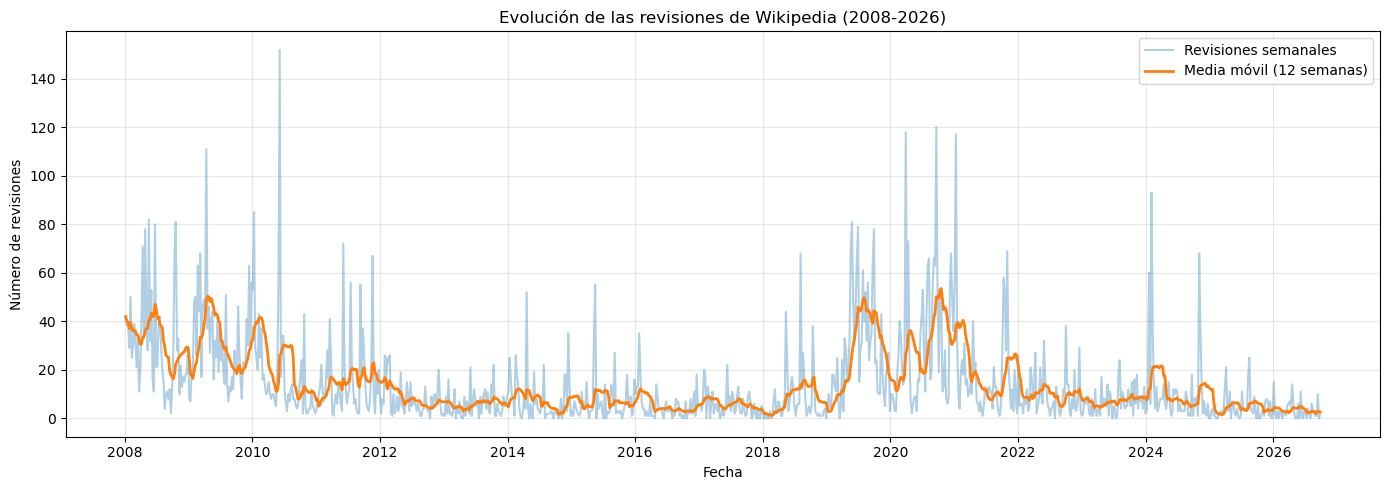

In [173]:
import matplotlib.pyplot as plt

# Calcular la media móvil de 12 semanas
df_volumen["media_movil_12"] = (
    df_volumen["volumen_revisiones"]
    .rolling(window=12, min_periods=1)
    .mean()
)

# Crear gráfico
plt.figure(figsize=(14, 5))

plt.plot(
    df_volumen["timestamp"],
    df_volumen["volumen_revisiones"],
    alpha=0.35,
    label="Revisiones semanales"
)

plt.plot(
    df_volumen["timestamp"],
    df_volumen["media_movil_12"],
    linewidth=2,
    label="Media móvil (12 semanas)"
)

plt.title("Evolución de las revisiones de Wikipedia (2008-2026)")
plt.xlabel("Fecha")
plt.ylabel("Número de revisiones")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

os.makedirs("figures", exist_ok=True)
plt.savefig("figures/volumen_semanal.png", dpi=300)
plt.show()

Lectura del volumen:
- La distribución es muy asimétrica: media de 13,8 revisiones por semana, pero mediana de 7 y máximo de 152 (semana del 6 de junio de 2010). Hay picos puntuales (2009, 2010, 2020 y 2021) que pueden deberse a disputas, reversiones o eventos; no se han investigado.
- En la hipótesis conviene usar la mediana, el logaritmo o variaciones, no solo la media, para que los picos no dominen.
- Se descargan 13.470 revisiones y se cuentan 13.469: la que sobra es posterior a la última semana del dataset.
- El volumen incluye ediciones de bots y reversiones, y es del artículo completo, no solo de la entradilla.

In [174]:
df_volumen["timestamp"] = df_volumen["timestamp"].dt.tz_localize(None)
df_volumen["mes"] = df_volumen["timestamp"].dt.to_period("M").astype(str)

volumen_mensual = df_volumen.groupby("mes").agg(
    revisiones_por_semana=("volumen_revisiones", "mean"),
    revisiones_total=("volumen_revisiones", "sum"),
).reset_index()

df_volumen.to_csv("data/processed/volumen_semanal.csv", index=False)
volumen_mensual.to_csv("data/processed/volumen_mensual.csv", index=False)
display(volumen_mensual.head())

,mes,revisiones_por_semana,revisiones_total
0,2008-01,37.00,148
1,2008-02,35.75,143
2,2008-03,23.40,117
3,2008-04,55.75,223
4,2008-05,45.00,180


## 2.2. Sentimiento medio agregado

El enunciado pide polaridad (positivo / negativo / neutro) por intervalo temporal con un **modelo en español predefinido**. Los textos están en inglés, así que el plan es:

1. Traducir al español los textos únicos (`Helsinki-NLP/opus-mt-en-es`).
2. Aplicar un modelo de sentimiento en español.
3. Agregar el resultado por intervalo temporal.

> Alternativa a valorar: un modelo multilingüe (p. ej. `cardiffnlp/twitter-xlm-roberta-base-sentiment`) evitaría la traducción, pero el enunciado habla de un modelo en español.

### 2.2.1. Traducción: dividir los textos en frases

Se traduce **frase a frase**: las frases cortas se traducen mejor que bloques largos, y como los textos cambian poco entre semanas, cada frase distinta solo hay que traducirla una vez.

In [175]:
import torch
from tqdm.auto import tqdm
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

RUTA_TRAD = "data/processed/traducciones.csv"
MODELO = "Helsinki-NLP/opus-mt-en-es"
BATCH = 16


def dividir_frases(texto):
    return [f for f in re.split(r"(?<=[.!?])\s+(?=[A-Z\"“(])", texto) if f]


frases_por_texto = {t: dividir_frases(t) for t in df_unique["text_clean"]}
frases = sorted({f for fs in frases_por_texto.values() for f in fs}, key=len)   # por longitud: menos relleno en los lotes

# Traducciones ya guardadas: si se interrumpe, se reanuda sin repetir trabajo
cache = {}
if os.path.exists(RUTA_TRAD):
    previo = pd.read_csv(RUTA_TRAD)
    cache = dict(zip(previo["en"], previo["es"]))
pendientes = [f for f in frases if f not in cache]
print(f"Frases únicas: {len(frases)} | ya traducidas: {len(cache)} | pendientes: {len(pendientes)}")


def guardar_cache():
    pd.DataFrame({"en": list(cache), "es": list(cache.values())}).to_csv(RUTA_TRAD, index=False)


if pendientes:
    dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
    tokenizer = AutoTokenizer.from_pretrained(MODELO)
    modelo = AutoModelForSeq2SeqLM.from_pretrained(MODELO).to(dispositivo).eval()

    for i in tqdm(range(0, len(pendientes), BATCH)):
        lote = pendientes[i:i + BATCH]
        entradas = tokenizer(lote, return_tensors="pt", padding=True,
                             truncation=True, max_length=512).to(dispositivo)
        with torch.inference_mode():
            salidas = modelo.generate(**entradas, max_new_tokens=512, num_beams=1)
        cache.update(zip(lote, tokenizer.batch_decode(salidas, skip_special_tokens=True)))
        if (i // BATCH) % 20 == 0:
            guardar_cache()
    guardar_cache()

# Texto completo en español de cada texto único (y de cada semana)
df_unique["text_es"] = df_unique["text_clean"].map(lambda t: " ".join(cache[f] for f in frases_por_texto[t]))
df_clean["text_es"] = df_clean["text_clean"].map(dict(zip(df_unique["text_clean"], df_unique["text_es"])))
print(df_unique["text_es"].iloc[0][:300])

Frases únicas: 1072 | ya traducidas: 1194 | pendientes: 0
El calentamiento global es el aumento de la temperatura media del aire y los océanos cercanos a la superficie de la Tierra en las últimas décadas y su continuación proyectada. La temperatura media mundial del aire cerca de la superficie terrestre aumentó 0,74 ± 0,18 °C (1,33 ± 0,32 °F) durante el pe


### 2.2.2. Cargar el modelo de sentimiento en español

**Decisión:** `pysentimiento/robertuito-sentiment-analysis` (RoBERTuito, español; etiquetas NEG / NEU / POS). Se probó también `finiteautomata/beto-sentiment-analysis`, pero da probabilidades casi siempre ~0 o ~1 y al promediar muchas frases se pierde el matiz; RoBERTuito devuelve probabilidades más graduadas, que es lo que necesitamos para agregar por intervalo.

**Limitaciones que hay que anotar en `motivation.md`:**
- El modelo se entrenó con **tuits**; aquí se aplica a texto enciclopédico traducido, así que mide más el tono (p. ej. temas de consecuencias o riesgos suenan "negativos") que una opinión.
- Acepta como máximo 128 tokens: las frases más largas se trocean por comas y puntos y coma.

In [176]:
from transformers import pipeline

MODELO_SENT = "pysentimiento/robertuito-sentiment-analysis"

clasificador = pipeline(
    "text-classification",
    model=MODELO_SENT,
    top_k=None,                                   # devolver las 3 probabilidades
    device=0 if torch.cuda.is_available() else -1,
    truncation=True,
    max_length=128,
)
tokenizer_sent = clasificador.tokenizer

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: pysentimiento/robertuito-sentiment-analysis
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


### 2.2.3. Calcular el sentimiento de cada texto único

El sentimiento se calcula **por frase** y se promedia por texto; solo se evalúan las frases únicas ya traducidas, no las 978 semanas. Las frases de más de 120 tokens se trocean antes de pasarlas al modelo.

In [177]:
def trocear(frase, max_tokens=120):
    """Divide una frase larga por comas/puntos y comas para que quepa en el modelo."""
    if len(tokenizer_sent.tokenize(frase)) <= max_tokens:
        return [frase]
    partes, actual = [], ""
    for trozo in re.split(r"(?<=[,;:])\s+", frase):
        candidato = f"{actual} {trozo}".strip()
        if actual and len(tokenizer_sent.tokenize(candidato)) > max_tokens:
            partes.append(actual)
            actual = trozo
        else:
            actual = candidato
    if actual:
        partes.append(actual)
    return partes


frases_es = sorted(set(cache.values()))
piezas = {f: trocear(f) for f in frases_es}
unicas = sorted({p for ps in piezas.values() for p in ps})
print(f"Frases en español: {len(frases_es)} | piezas a clasificar: {len(unicas)}")

salida = clasificador(unicas, batch_size=32)
puntos = {p: {x["label"]: x["score"] for x in o} for p, o in zip(unicas, salida)}

# sentimiento de la frase = media de sus piezas
sent_frases = pd.DataFrame(
    {f: pd.DataFrame([puntos[p] for p in ps]).mean() for f, ps in piezas.items()}
).T
display(sent_frases.describe().round(2))

def sentimiento_texto(texto_en):
    frases_es_texto = [cache[f] for f in frases_por_texto[texto_en]]
    return sent_frases.loc[frases_es_texto].mean()


sent_textos = df_unique["text_clean"].apply(sentimiento_texto)

df_unique["p_neg"] = sent_textos["NEG"].values
df_unique["p_neu"] = sent_textos["NEU"].values
df_unique["p_pos"] = sent_textos["POS"].values
df_unique["sent_score"] = df_unique["p_pos"] - df_unique["p_neg"]
df_unique["sent_label"] = (
    sent_textos[["NEG", "NEU", "POS"]].idxmax(axis=1)
    .map({"NEG": "negativo", "NEU": "neutro", "POS": "positivo"}).values
)

print(df_unique["sent_label"].value_counts())
print(df_unique[["p_neg", "p_neu", "p_pos", "sent_score"]].describe().round(3))

Token indices sequence length is longer than the specified maximum sequence length for this model (136 > 128). Running this sequence through the model will result in indexing errors


Frases en español: 1117 | piezas a clasificar: 1179


,NEG,NEU,POS
count,1117.00,1117.00,1117.00
mean,0.40,0.51,0.09
std,0.27,0.22,0.10
min,0.03,0.02,0.00
25%,0.17,0.34,0.03
50%,0.34,0.55,0.06
75%,0.62,0.69,0.11
max,0.98,0.92,0.74


sent_label
neutro      308
negativo     68
Name: count, dtype: int64
         p_neg    p_neu    p_pos  sent_score
count  376.000  376.000  376.000     376.000
mean     0.377    0.525    0.098      -0.279
std      0.078    0.074    0.019       0.085
min      0.203    0.373    0.056      -0.451
25%      0.313    0.455    0.084      -0.336
50%      0.396    0.520    0.097      -0.301
75%      0.436    0.590    0.110      -0.212
max      0.539    0.671    0.155      -0.077


### 2.2.4. Agregar por intervalo temporal y visualizar

Se lleva el sentimiento de cada texto a la serie semanal (unión por `text_id`) y se agrega por **mes**: puntuación media, probabilidades medias y porcentaje de semanas de cada clase. También se guarda la serie semanal.

In [178]:
cols_sent = ["p_neg", "p_neu", "p_pos", "sent_score", "sent_label"]

df_clean = (
    df_clean.drop(columns=cols_sent, errors="ignore")
    .merge(df_unique[["text_id"] + cols_sent], on="text_id", how="left")
)
print("Semanas sin sentimiento:", df_clean["sent_score"].isna().sum())

sent_semanal = df_clean[["timestamp", "text_id"] + cols_sent]

sent_mensual = df_clean.groupby("mes").agg(
    sent_medio=("sent_score", "mean"),
    p_neg=("p_neg", "mean"),
    p_neu=("p_neu", "mean"),
    p_pos=("p_pos", "mean"),
    n_semanas=("sent_score", "size"),
)
clases = pd.crosstab(df_clean["mes"], df_clean["sent_label"], normalize="index").add_prefix("pct_")
sent_mensual = sent_mensual.join(clases).reset_index()

sent_semanal.to_csv("data/processed/sentimiento_semanal.csv", index=False)
sent_mensual.to_csv("data/processed/sentimiento_mensual.csv", index=False)
display(sent_mensual.head())

Semanas sin sentimiento: 0


,mes,sent_medio,p_neg,p_neu,p_pos,n_semanas,pct_negativo,pct_neutro
0,2008-01,-0.222503,0.313769,0.594964,0.091266,4,0.0,1.0
1,2008-02,-0.214033,0.305614,0.602806,0.091580,4,0.0,1.0
2,2008-03,-0.205393,0.299217,0.606958,0.093824,5,0.0,1.0
3,2008-04,-0.198566,0.292697,0.613171,0.094132,4,0.0,1.0
4,2008-05,-0.200298,0.294257,0.611783,0.093960,4,0.0,1.0


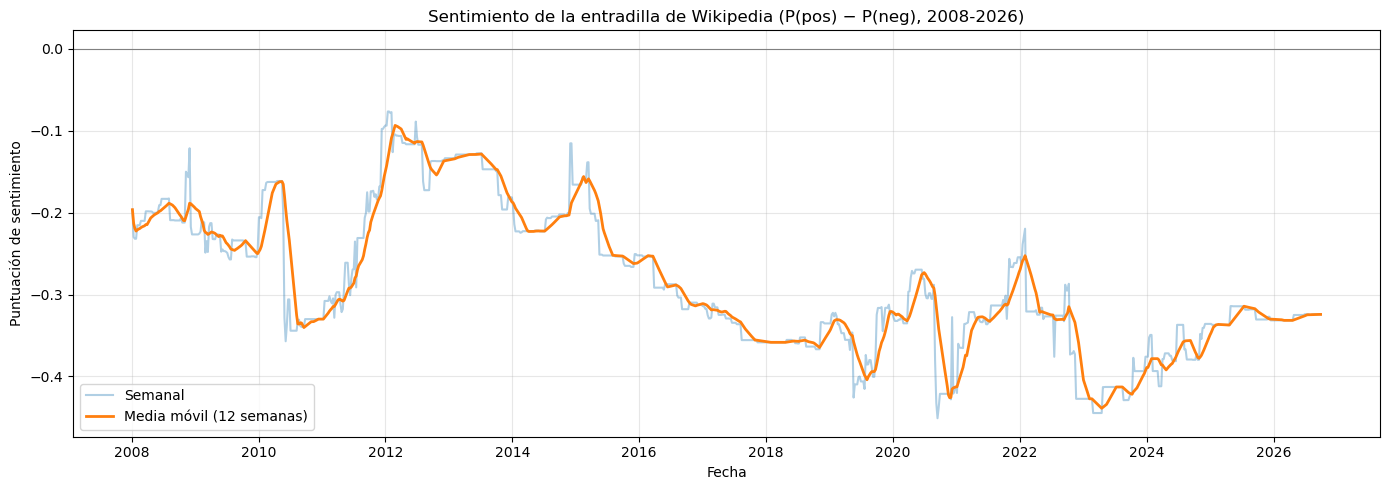

In [179]:
sent_semanal = sent_semanal.sort_values("timestamp")
media_movil = sent_semanal["sent_score"].rolling(12, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sent_semanal["timestamp"], sent_semanal["sent_score"], alpha=0.35, label="Semanal")
ax.plot(sent_semanal["timestamp"], media_movil, linewidth=2, label="Media móvil (12 semanas)")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_title("Sentimiento de la entradilla de Wikipedia (P(pos) − P(neg), 2008-2026)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Puntuación de sentimiento")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/sentimiento.png", dpi=300)
plt.show()

### 2.2.5. Cómo leer el sentimiento

- **Tono general:** el 84 % de las semanas es neutra y el 16 % negativa; ninguna es positiva. La puntuación mensual va de −0,445 (marzo de 2023) a −0,084 (enero de 2012).
- **Evolución:** la media anual pasa de −0,20 en 2008 y −0,12 en 2012 a −0,33 / −0,36 en 2017-2019 y −0,42 en 2023. El tono se va volviendo más negativo, aunque las diferencias son pequeñas.
- **Cómo interpretarlo:** el modelo mide el tono del contenido (riesgos, consecuencias, pérdidas), no una opinión. Que el sentimiento sea siempre neutro o negativo es esperable en una entradilla enciclopédica sobre cambio climático. Lo interesante no es el valor absoluto, sino su variación entre épocas.
- **Limitación:** el modelo se entrenó con tuits y se aplica a texto traducido automáticamente (ver 2.2.2).

## 2.3. Distribución de tópicos

El enunciado pide aplicar un modelo de tópicos (LDA o BERTopic) y mostrar la **proporción de tópicos por intervalo temporal**.

### 2.3.1. Elegir el modelo y preparar el corpus

**Decisión 1: LDA (gensim).** Solo hay 376 textos distintos y casi todos son revisiones del mismo artículo. BERTopic agrupa documentos con UMAP + HDBSCAN, que previsiblemente es inestable con tan pocos documentos tan parecidos (no se ha probado); LDA da directamente una distribución de tópicos, que es justo lo que hay que agregar por intervalo.

**Decisión 2: entrenar sobre frases, no sobre textos completos.** Un primer intento con los textos enteros dio tópicos que eran en realidad *épocas* de la entradilla (cada texto caía casi al 100 % en un solo tópico). Entrenando con las **frases únicas** (unas 1.000) los tópicos son temáticos, y la distribución de un texto se obtiene promediando la de sus frases (ponderada por su longitud). Así cada texto es una *mezcla* de tópicos y la proporción mensual es una distribución de verdad.

El corpus son las frases en inglés (`text_clean`), no las traducidas, para no arrastrar errores de traducción. Preprocesado: minúsculas, solo palabras, lematización (spaCy), y fuera las palabras vacías y las que están en todos los textos (*climate*, *change*, *global*, *warming*...).

In [180]:
!pip install -q gensim spacy
!python -m spacy download en_core_web_sm -q

import numpy as np
import spacy
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
PALABRAS_VACIAS = set(ENGLISH_STOP_WORDS) | {
    "climate", "change", "global", "warming", "ipcc", "accord", "use", "also",
    "mdash", "ndash", "cause", "include", "year", "many", "new",
}


def preparar(texto):
    lemas = (t.lemma_.lower() for t in nlp(texto) if t.is_alpha and len(t) > 2)
    return [w for w in lemas if len(w) > 2 and w not in PALABRAS_VACIAS]


# Frases únicas (las mismas que se tradujeron en 2.2.1)
frases_unicas = sorted({f for fs in frases_por_texto.values() for f in fs})
docs_todas = [preparar(f) for f in frases_unicas]
print("Frases únicas:", len(frases_unicas))
print("Ejemplo:", frases_unicas[0][:100], "->", docs_todas[0][:10])

# Quitar palabras muy raras (< 5 frases) o muy frecuentes (> 50 % de las frases)
diccionario = Dictionary(docs_todas)
diccionario.filter_extremes(no_below=5, no_above=0.5)

# Solo se entrena con frases que conserven al menos 3 palabras útiles
MIN_PALABRAS = 3
corpus_todas = [diccionario.doc2bow(d) for d in docs_todas]
usadas = [i for i, bow in enumerate(corpus_todas) if len(bow) >= MIN_PALABRAS]

frases_lda = [frases_unicas[i] for i in usadas]
docs = [docs_todas[i] for i in usadas]
corpus = [corpus_todas[i] for i in usadas]
print(f"Vocabulario: {len(diccionario)} | frases usadas para entrenar: {len(corpus)} de {len(frases_unicas)}")

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
Frases únicas: 1072
Ejemplo: "'Climate change' and 'global warming' are often used interchangeably but have distinct meanings.... -> ['interchangeably', 'distinct', 'meaning']
Vocabulario: 588 | frases usadas para entrenar: 1023 de 1072


### 2.3.2. Elegir el número de tópicos

Se entrena LDA con 3 a 8 tópicos y se compara la **coherencia c_v** (más alta = tópicos más interpretables). Con frases tan parecidas la curva es bastante plana, así que la coherencia sola no decide: también se leen las palabras de cada tópico.

In [181]:
coherencias = {}
for k in range(3, 9):
    lda = LdaModel(corpus, num_topics=k, id2word=diccionario, passes=20,
                   iterations=200, alpha="auto", eta="auto", random_state=0)
    coherencias[k] = CoherenceModel(model=lda, texts=docs, dictionary=diccionario,
                                    coherence="c_v", processes=1).get_coherence()
    print(f"{k} tópicos -> coherencia c_v = {coherencias[k]:.3f}")

3 tópicos -> coherencia c_v = 0.456
4 tópicos -> coherencia c_v = 0.435
5 tópicos -> coherencia c_v = 0.437
6 tópicos -> coherencia c_v = 0.435
7 tópicos -> coherencia c_v = 0.451
8 tópicos -> coherencia c_v = 0.479


**Decisión: 5 tópicos.** La coherencia c_v apenas distingue entre 3 y 8 tópicos (0,44 a 0,48) y 5 no es el máximo (el máximo es 8, con 0,479), así que la elección se hace por interpretabilidad: con 5 se leen cinco temas distintos (efectos físicos como temperatura, hielo y nivel del mar; sistema terrestre y tiempo; ciencia y salud; mitigación y límites de emisiones; energía y combustibles fósiles) y hay margen para que los textos se repartan entre varios. Más tópicos darían una coherencia algo mayor, pero con tan pocas frases cada tópico quedaría con muy pocos ejemplos; con menos, se mezclarían temas.

**Limitaciones que se ven en los resultados** (anotar en `motivation.md`):
- Los tópicos comparten palabras (*temperature*, *increase*, *greenhouse*, *emission*), porque todas las frases hablan de lo mismo; los nombres automáticos de tres palabras solo son orientativos.
- El tópico T2 (ciencia y salud) es el más débil: es el principal en solo 3 de los 376 textos, aunque pesa un 15 % de media.

Se puede cambiar `N_TOPICOS` y volver a ejecutar.

In [182]:
N_TOPICOS = 5

modelo_lda = LdaModel(corpus, num_topics=N_TOPICOS, id2word=diccionario, passes=20,
                      iterations=200, alpha="auto", eta="auto", random_state=0)

# Nombre de cada tópico = sus 3 palabras más representativas
nombres_topicos = {}
for t in range(N_TOPICOS):
    palabras = [w for w, _ in modelo_lda.show_topic(t, 8)]
    nombres_topicos[t] = f"T{t}: " + ", ".join(palabras[:3])
    print(nombres_topicos[t], "|", ", ".join(palabras))

T0: temperature, sea, rise | temperature, sea, rise, effect, increase, ice, surface, level
T1: effect, temperature, century | effect, temperature, century, earth, ocean, weather, increase, greenhouse
T2: emission, century, human | emission, century, human, science, health, national, academy, scientific
T3: emission, limit, report | emission, limit, report, temperature, likely, greenhouse, gas, increase
T4: increase, gas, temperature | increase, gas, temperature, greenhouse, carbon, fossil, fuel, energy


### 2.3.3. Proporción de cada tópico por intervalo temporal y visualización

1. Cada frase recibe una distribución de tópicos.
2. La distribución de un texto es la media de la de sus frases, ponderada por el número de palabras útiles de cada frase.
3. Se lleva a cada semana (unión por `text_id`) y se agrega por mes con la media: la proporción media de cada tópico en ese mes.

In [183]:
cols_top = [f"topico_{t}" for t in range(N_TOPICOS)]

theta_frase, peso_frase = {}, {}
for frase, bow in zip(frases_lda, corpus):
    theta_frase[frase] = np.array(
        [p for _, p in modelo_lda.get_document_topics(bow, minimum_probability=0)]
    )
    peso_frase[frase] = sum(n for _, n in bow)


def theta_texto(texto):
    fs = [f for f in frases_por_texto[texto] if f in theta_frase]
    pesos = np.array([peso_frase[f] for f in fs], dtype=float)
    return (np.array([theta_frase[f] for f in fs]) * pesos[:, None]).sum(axis=0) / pesos.sum()


theta = np.array([theta_texto(t) for t in df_unique["text_clean"]])
df_unique[cols_top] = theta
df_unique["topico_dominante"] = theta.argmax(axis=1)

print("Proporción media de cada tópico:", theta.mean(axis=0).round(2))
print("Proporción media del tópico principal de un texto:", theta.max(axis=1).mean().round(2))
print("Textos por tópico dominante:\n", df_unique["topico_dominante"].value_counts().sort_index())

df_clean = (
    df_clean.drop(columns=cols_top + ["topico_dominante"], errors="ignore")
    .merge(df_unique[["text_id"] + cols_top + ["topico_dominante"]], on="text_id", how="left")
)

topicos_semanal = df_clean[["timestamp", "text_id"] + cols_top + ["topico_dominante"]]
topicos_mensual = df_clean.groupby("mes")[cols_top].mean().reset_index()

topicos_semanal.to_csv("data/processed/topicos_semanal.csv", index=False)
topicos_mensual.to_csv("data/processed/topicos_mensual.csv", index=False)
display(topicos_mensual.head())

Proporción media de cada tópico: [0.21 0.19 0.15 0.27 0.18]
Proporción media del tópico principal de un texto: 0.35
Textos por tópico dominante:
 topico_dominante
0    103
1     82
2      3
3    141
4     47
Name: count, dtype: int64


,mes,topico_0,topico_1,topico_2,topico_3,topico_4
0,2008-01,0.166741,0.295085,0.195366,0.240131,0.102677
1,2008-02,0.150035,0.301621,0.192556,0.242011,0.113777
2,2008-03,0.142951,0.306349,0.190682,0.239655,0.120364
3,2008-04,0.133721,0.291461,0.189617,0.238317,0.146885
4,2008-05,0.132705,0.293900,0.188177,0.236507,0.148711


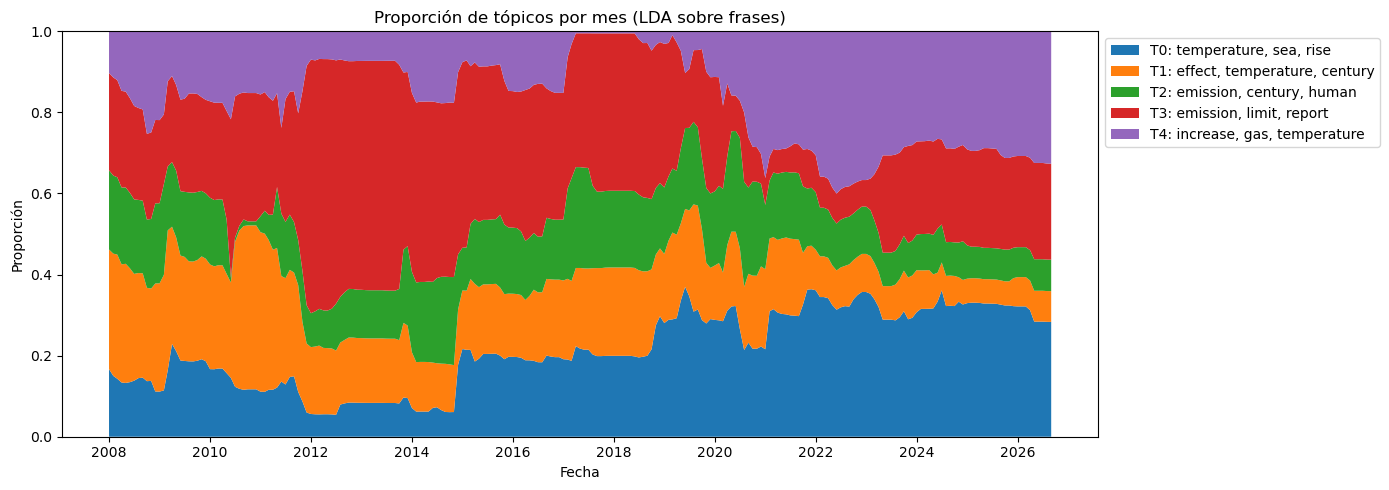

In [184]:
fechas_mes = pd.to_datetime(topicos_mensual["mes"])

fig, ax = plt.subplots(figsize=(14, 5))
ax.stackplot(
    fechas_mes,
    [topicos_mensual[c] for c in cols_top],
    labels=[nombres_topicos[t] for t in range(N_TOPICOS)],
)
ax.set_title("Proporción de tópicos por mes (LDA sobre frases)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Proporción")
ax.set_ylim(0, 1)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/topicos.png", dpi=300, bbox_inches="tight")
plt.show()

In [185]:
display(df_clean.groupby("anio")[cols_top].mean().round(2).rename(columns=lambda c: nombres_topicos[int(c.split("_")[1])]))

,"T0: temperature, sea, rise","T1: effect, temperature, century","T2: emission, century, human","T3: emission, limit, report","T4: increase, gas, temperature"
anio,,,,,
2008,0.14,0.27,0.19,0.23,0.17
2009,0.18,0.27,0.17,0.22,0.16
2010,0.14,0.32,0.07,0.30,0.17
2011,0.12,0.29,0.11,0.32,0.16
2012,0.07,0.16,0.10,0.60,0.07
2013,0.09,0.16,0.13,0.54,0.08
2014,0.07,0.12,0.20,0.44,0.17
2015,0.20,0.17,0.15,0.39,0.09
2016,0.19,0.17,0.15,0.35,0.14


**Lo que muestra la tabla por año:**
- **T3 (emisiones y límites):** domina en 2012-2013 (0,60 y 0,54) y cae a 0,07-0,08 en 2021-2022.
- **T4 (energía y combustibles fósiles):** casi no aparece en 2017-2018 (0,02-0,03) y sube a 0,37 en 2022.
- **T0 (temperatura, hielo, nivel del mar):** pasa de 0,07 en 2012-2014 a 0,31-0,34 desde 2019.
- **T1 (efectos y tiempo atmosférico):** baja de 0,32 (2010) a 0,06 (2025).

Es decir, el contenido de la entradilla cambia de foco con los años: de las emisiones y los acuerdos, a los efectos físicos y la energía.

**Cómo usarlo (y cómo no):**
- La proporción de cada tópico va muy ligada al tiempo. Correlacionarla con series que también tienen tendencia (CO₂, temperatura) da relaciones engañosas: por eso en 2.4.1 se muestran también las variaciones mes a mes. En la hipótesis hay que comparar épocas o trabajar con variaciones.
- Los tópicos se han entrenado con pocas frases muy parecidas entre sí: son orientativos, no una taxonomía cerrada.

## 2.4. Tabla conjunta de los indicadores obligatorios

Se juntan volumen, sentimiento y tópicos (todos mensuales) con la media mensual de las series numéricas del dataset. Esta tabla es la base para formular y contrastar la hipótesis (secciones 3 y 4).

In [186]:
numericas_mensual = df_clean.groupby("mes")[COLS_NUM].mean().reset_index()

indicadores_mensual = (
    volumen_mensual
    .merge(sent_mensual[["mes", "sent_medio", "p_neg", "p_neu", "p_pos"]], on="mes")
    .merge(topicos_mensual, on="mes")
    .merge(numericas_mensual, on="mes")
)

indicadores_mensual.to_csv("data/processed/indicadores_mensual.csv", index=False)
print("Meses:", len(indicadores_mensual), "| columnas:", len(indicadores_mensual.columns))
display(indicadores_mensual.head())

Meses: 225 | columnas: 20


,mes,revisiones_por_semana,revisiones_total,sent_medio,p_neg,p_neu,p_pos,topico_0,topico_1,topico_2,topico_3,topico_4,co2_ppm,brent_price,temp_anomaly_c,ch4_ppb,n2o_ppb,oni_anomaly,media_volume_norm,rev_size
0,2008-01,37.00,148,-0.222503,0.313769,0.594964,0.091266,0.166741,0.295085,0.195366,0.240131,0.102677,385.9975,91.597498,0.50,1788.04,321.062,-1.72,0.001390,92011.25
1,2008-02,35.75,143,-0.214033,0.305614,0.602806,0.091580,0.150035,0.301621,0.192556,0.242011,0.113777,385.9025,94.032501,0.30,1786.69,321.167,-1.76,0.005998,94236.25
2,2008-03,23.40,117,-0.205393,0.299217,0.606958,0.093824,0.142951,0.306349,0.190682,0.239655,0.120364,386.6740,101.310002,0.38,1785.82,321.184,-1.61,0.000445,95550.20
3,2008-04,55.75,223,-0.198566,0.292697,0.613171,0.094132,0.133721,0.291461,0.189617,0.238317,0.146885,387.2000,112.037498,0.75,1786.15,321.167,-1.37,0.014697,95826.00
4,2008-05,45.00,180,-0.200298,0.294257,0.611783,0.093960,0.132705,0.293900,0.188177,0.236507,0.148711,388.9575,124.382502,0.54,1786.90,321.223,-1.05,0.004647,97749.25


### 2.4.1. Primera mirada: correlaciones entre indicadores

Se muestran la matriz en **niveles** y la de **variaciones mes a mes** (diferencias entre un mes y el anterior).
- En niveles salen correlaciones muy altas (p. ej. el tópico T0 con el CO₂, 0,84; el sentimiento con el CO₂, −0,68), pero son tendencias compartidas a lo largo de los años, no relaciones reales.
- En variaciones desaparecen: ningún indicador supera |r| = 0,20 con CO₂, temperatura, ONI o Brent. Entre indicadores las relaciones son débiles (más revisiones con sentimiento algo más negativo, −0,23; el sentimiento baja cuando sube T4, −0,29), y las correlaciones negativas entre tópicos son en parte mecánicas porque las proporciones suman 1.
- Para la hipótesis conviene, por tanto, mirar cambios del texto entre épocas o frente a eventos concretos, no correlaciones con las series climáticas.

In [187]:
cols_resumen = ["revisiones_por_semana", "sent_medio"] + cols_top + ["co2_ppm", "temp_anomaly_c", "oni_anomaly", "brent_price"]
tabla = indicadores_mensual[cols_resumen]

print("Correlaciones en niveles:")
display(tabla.corr().round(2))

print("Correlaciones en variaciones mes a mes:")
display(tabla.diff().dropna().corr().round(2))

Correlaciones en niveles:


,revisiones_por_semana,sent_medio,topico_0,topico_1,topico_2,topico_3,topico_4,co2_ppm,temp_anomaly_c,oni_anomaly,brent_price
revisiones_por_semana,1.00,-0.02,0.00,0.36,0.30,-0.31,-0.00,-0.25,-0.22,-0.13,-0.11
sent_medio,-0.02,1.00,-0.74,0.20,0.08,0.63,-0.38,-0.68,-0.57,-0.05,0.40
topico_0,0.00,-0.74,1.00,-0.50,-0.13,-0.74,0.55,0.84,0.69,0.16,-0.39
topico_1,0.36,0.20,-0.50,1.00,0.15,0.08,-0.48,-0.76,-0.65,-0.31,0.01
topico_2,0.30,0.08,-0.13,0.15,1.00,-0.07,-0.40,-0.22,-0.19,0.10,-0.34
topico_3,-0.31,0.63,-0.74,0.08,-0.07,1.00,-0.70,-0.46,-0.32,0.14,0.30
topico_4,-0.00,-0.38,0.55,-0.48,-0.40,-0.70,1.00,0.55,0.39,-0.14,0.10
co2_ppm,-0.25,-0.68,0.84,-0.76,-0.22,-0.46,0.55,1.00,0.80,0.17,-0.23
temp_anomaly_c,-0.22,-0.57,0.69,-0.65,-0.19,-0.32,0.39,0.80,1.00,0.49,-0.37
oni_anomaly,-0.13,-0.05,0.16,-0.31,0.10,0.14,-0.14,0.17,0.49,1.00,-0.33


Correlaciones en variaciones mes a mes:


,revisiones_por_semana,sent_medio,topico_0,topico_1,topico_2,topico_3,topico_4,co2_ppm,temp_anomaly_c,oni_anomaly,brent_price
revisiones_por_semana,1.00,-0.23,0.04,-0.27,-0.12,0.05,0.22,0.02,0.05,0.01,-0.02
sent_medio,-0.23,1.00,0.10,-0.08,0.18,0.11,-0.29,0.12,0.06,0.13,-0.05
topico_0,0.04,0.10,1.00,-0.07,-0.18,-0.30,-0.24,0.14,0.01,0.11,-0.10
topico_1,-0.27,-0.08,-0.07,1.00,-0.01,-0.30,-0.38,-0.10,-0.06,-0.20,-0.04
topico_2,-0.12,0.18,-0.18,-0.01,1.00,-0.49,-0.01,0.05,0.07,0.15,0.05
topico_3,0.05,0.11,-0.30,-0.30,-0.49,1.00,-0.38,-0.02,0.03,-0.02,0.04
topico_4,0.22,-0.29,-0.24,-0.38,-0.01,-0.38,1.00,-0.04,-0.05,-0.02,0.02
co2_ppm,0.02,0.12,0.14,-0.10,0.05,-0.02,-0.04,1.00,0.02,0.05,0.05
temp_anomaly_c,0.05,0.06,0.01,-0.06,0.07,0.03,-0.05,0.02,1.00,0.12,0.00
oni_anomaly,0.01,0.13,0.11,-0.20,0.15,-0.02,-0.02,0.05,0.12,1.00,-0.02


# 3. Indicador opcional (elegir solo 1)

Opciones del enunciado: **diversidad léxica** (riqueza de vocabulario / entropía de Shannon), **similitud semántica** (entre embeddings), **palabras clave** (términos cuya frecuencia aumenta súbitamente) o **clasificación temática asistida por LLM**.

## 3.1. Elegir el indicador y justificarlo

**Elegido: palabras clave** (términos cuya frecuencia aumenta de golpe).

- **Encaja con los datos.** La entradilla no cambia poco a poco: se reescribe en momentos concretos (los tópicos del apartado 2.3 cambian de foco por épocas). Un término que "entra de golpe" señala *qué* entra en el texto y *cuándo*.
- **Complementa a los otros tres indicadores.** El volumen mide cuánto se edita, el sentimiento el tono, los tópicos los grandes temas; las palabras clave dan los términos concretos y las fechas de los cambios, y se pueden contrastar con hechos externos (informes del IPCC, acuerdos, eventos).
- **Es interpretable y barato.** No necesita modelos pesados ni embeddings.

**Descartadas:**
- *Diversidad léxica:* con textos de longitud y estilo parecidos sería casi constante y aportaría poco.
- *Similitud semántica:* exige embeddings y repite lo que ya sabemos (la entradilla cambia poco entre semanas: el 62 % de las semanas repite el texto anterior).
- *Clasificación con LLM:* coste, y las clases las decidiríamos nosotros (subjetivo).

## 3.2. Frecuencia de cada término en cada texto

Se reutiliza el preprocesado de 2.3 (minúsculas, lematización, sin palabras vacías). Dos decisiones:
- La frecuencia se da **por 1.000 palabras**, no en bruto, porque la longitud de los textos varía mucho (de ~250 a ~1.200 palabras) y un texto largo tendría más apariciones de todo.
- Solo se consideran términos que aparecen en **al menos 3 textos distintos**, para ignorar erratas y términos de una sola edición.

In [188]:
from sklearn.feature_extraction.text import CountVectorizer

docs_texto = [preparar(t) for t in df_unique["text_clean"]]

vectorizador = CountVectorizer(analyzer=lambda d: d, min_df=3)   # docs ya tokenizados
conteos = vectorizador.fit_transform(docs_texto).toarray().astype(float)
terminos = vectorizador.get_feature_names_out()

longitud = np.array([len(d) for d in docs_texto])[:, None]
frec_texto = conteos / longitud * 1000                           # apariciones por 1.000 palabras
print("Términos considerados:", len(terminos), "| textos:", frec_texto.shape[0])

# Matriz semanal: la fila de cada semana es la del texto vigente esa semana
serie = df_clean.sort_values("timestamp").reset_index(drop=True)
fila_texto = {tid: i for i, tid in enumerate(df_unique["text_id"])}
frec_semanal = frec_texto[serie["text_id"].map(fila_texto).values]
print("Matriz semana x término:", frec_semanal.shape)

Términos considerados: 1011 | textos: 376
Matriz semana x término: (978, 1011)


## 3.3. Detectar los aumentos súbitos

Para cada semana y cada término se compara la frecuencia media de las **12 semanas siguientes** con la de las **12 anteriores**. Un término está "en auge" si cumple las dos condiciones:
- **Aparece con fuerza después:** al menos 3 apariciones por 1.000 palabras (≈ una aparición en un texto típico).
- **Salto grande:** su frecuencia se multiplica por 3 o más. Se suma 0,5 a ambas frecuencias para no dividir entre cero y no premiar saltos de 0 a casi 0.

De cada término se conserva su **salto más fuerte** (semana, frecuencia antes y después). Las 12 primeras y las 12 últimas semanas no se pueden evaluar porque les falta ventana.

In [189]:
VENTANA = 12        # semanas antes / después
FREC_MIN = 3.0      # apariciones por 1.000 palabras tras el salto
RATIO_MIN = 3.0     # la frecuencia se multiplica al menos por 3

n = len(frec_semanal)
acum = np.vstack([np.zeros(frec_semanal.shape[1]), np.cumsum(frec_semanal, axis=0)])
semanas_eval = np.arange(VENTANA, n - VENTANA + 1)

antes = (acum[semanas_eval] - acum[semanas_eval - VENTANA]) / VENTANA
despues = (acum[semanas_eval + VENTANA] - acum[semanas_eval]) / VENTANA

log_ratio = np.log2((despues + 0.5) / (antes + 0.5))
puntuacion = np.where(despues >= FREC_MIN, log_ratio, -np.inf)

mejor = puntuacion.argmax(axis=0)                   # semana del mayor salto de cada término
cols = np.arange(len(terminos))

# ¿el término aparece por primera vez en el texto, o ya había aparecido antes y reaparece?
primera_semana = (frec_semanal > 0).argmax(axis=0)  # primera semana en que aparece cada término

auge = pd.DataFrame({
    "termino": terminos,
    "semana": serie["timestamp"].values[semanas_eval[mejor]],
    "frec_antes": antes[mejor, cols],
    "frec_despues": despues[mejor, cols],
    "log2_ratio": puntuacion[mejor, cols],
    "primera_vez": primera_semana >= semanas_eval[mejor] - VENTANA,
})
auge["salto"] = auge["frec_despues"] - auge["frec_antes"]
auge = auge[auge["log2_ratio"] >= np.log2(RATIO_MIN)].sort_values("salto", ascending=False)
auge["mes"] = pd.to_datetime(auge["semana"]).dt.to_period("M").astype(str)
auge["anio"] = pd.to_datetime(auge["semana"]).dt.year

print(f"Términos en auge: {len(auge)} de {len(terminos)} "
      f"(aparecen por primera vez: {auge['primera_vez'].sum()}, reaparecen: {(~auge['primera_vez']).sum()})")
display(auge.head(20).round(2))

print("Términos en auge por año:")
print(auge.groupby("anio").size().to_string())

Términos en auge: 594 de 1011 (aparecen por primera vez: 393, reaparecen: 201)


,termino,semana,frec_antes,frec_despues,log2_ratio,primera_vez,salto,mes,anio
20,adaptation,2023-04-23,0.00,17.74,5.19,False,17.74,2023-04,2023
1005,world,2011-06-05,0.00,16.88,5.12,True,16.88,2011-06,2011
60,anthropogenic,2010-06-06,0.00,12.66,4.72,False,12.66,2010-06,2010
308,exceed,2011-06-05,0.00,12.42,4.69,True,12.42,2011-06,2011
636,party,2011-12-11,0.00,12.31,4.68,True,12.31,2011-12,2011
433,impact,2020-03-01,3.50,15.35,1.99,False,11.85,2020-03,2020
176,confidence,2023-04-23,0.00,11.83,4.62,False,11.83,2023-04,2023
19,adapt,2021-10-31,0.00,11.42,4.58,False,11.42,2021-10,2021
169,concentration,2009-05-31,0.00,10.87,4.51,False,10.87,2009-05,2009
514,limit,2011-06-05,0.00,10.84,4.50,True,10.84,2011-06,2011


Términos en auge por año:
anio
2008     20
2009     43
2010     41
2011    116
2012      3
2013      8
2014     27
2015      9
2016      2
2017      5
2018     13
2019     56
2020     86
2021     86
2022     49
2023     12
2024     18


## 3.4. Indicador por intervalo temporal y gráficos

Se cuenta cuántos términos tienen su salto más fuerte en cada mes (`terminos_en_auge`), cuántos de ellos aparecen por primera vez en el texto (`terminos_nuevos`; el resto son términos que ya estaban y reaparecen) y se guardan los 3 con más salto (`top_terminos`). Se añade también a la tabla conjunta mensual de 2.4.

In [190]:
meses = sorted(df_clean["mes"].unique())

n_por_mes = auge.groupby("mes").size().reindex(meses, fill_value=0)
nuevos_por_mes = auge[auge["primera_vez"]].groupby("mes").size().reindex(meses, fill_value=0)
top_por_mes = auge.groupby("mes")["termino"].apply(lambda s: ", ".join(s.head(3)))   # auge ya está ordenado por salto

palabras_mensual = pd.DataFrame({
    "mes": meses,
    "terminos_en_auge": n_por_mes.values,
    "terminos_nuevos": nuevos_por_mes.values,
    "top_terminos": [top_por_mes.get(m, "") for m in meses],
})

auge.to_csv("data/processed/palabras_clave_auge.csv", index=False)
palabras_mensual.to_csv("data/processed/palabras_clave_mensual.csv", index=False)

indicadores_mensual = (
    indicadores_mensual.drop(columns=["terminos_en_auge", "terminos_nuevos"], errors="ignore")
    .merge(palabras_mensual[["mes", "terminos_en_auge", "terminos_nuevos"]], on="mes", how="left")
)
indicadores_mensual.to_csv("data/processed/indicadores_mensual.csv", index=False)

display(palabras_mensual[palabras_mensual["terminos_en_auge"] > 0].sort_values("terminos_en_auge", ascending=False).head(10))

,mes,terminos_en_auge,terminos_nuevos,top_terminos
152,2020-09,36,21,"health, warm, result"
46,2011-11,28,26,"synthesis, uncertainty, observation"
157,2021-02,27,20,"infectious, flooding, food"
146,2020-03,27,14,"impact, development, technology"
165,2021-10,25,16,"adapt, absorb, far"
156,2021-01,24,15,"risk, people, consist"
39,2011-04,21,12,"country, national, major"
142,2019-11,18,7,"acidification, ocean, express"
41,2011-06,18,15,"world, exceed, limit"
14,2009-03,16,14,"responsible, middle, stop"


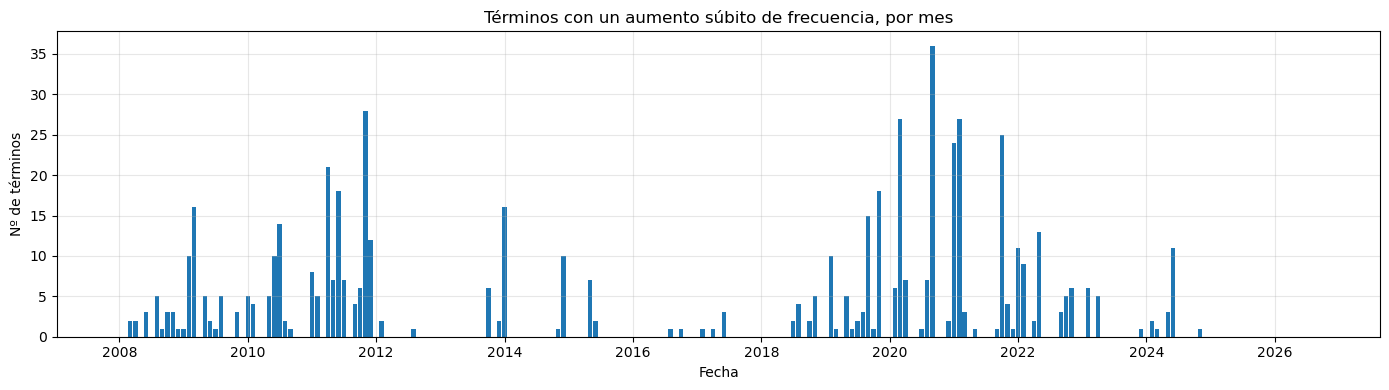

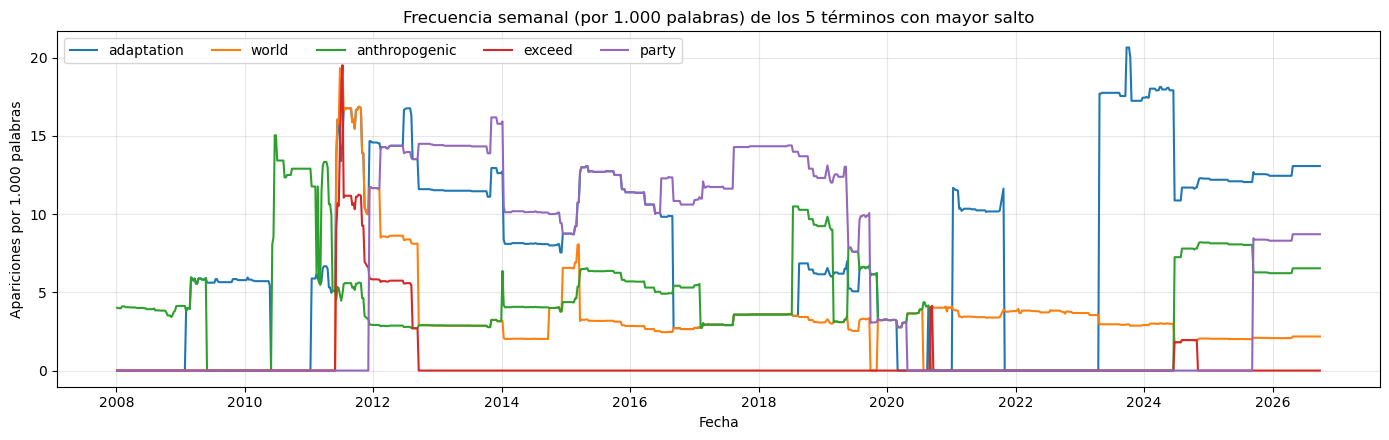

In [191]:
fechas_mes = pd.to_datetime(palabras_mensual["mes"])

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(fechas_mes, palabras_mensual["terminos_en_auge"], width=25)
ax.set_title("Términos con un aumento súbito de frecuencia, por mes")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nº de términos")
ax.grid(alpha=0.3)
fig.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/palabras_clave_mensual.png", dpi=300)
plt.show()

top5 = auge["termino"].head(5).tolist()
lista_terminos = list(terminos)

fig, ax = plt.subplots(figsize=(14, 4.5))
for t in top5:
    ax.plot(serie["timestamp"], frec_semanal[:, lista_terminos.index(t)], label=t)
ax.set_title("Frecuencia semanal (por 1.000 palabras) de los 5 términos con mayor salto")
ax.set_xlabel("Fecha")
ax.set_ylabel("Apariciones por 1.000 palabras")
ax.legend(ncol=5)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/palabras_clave_top5.png", dpi=300)
plt.show()

## 3.5. Cómo leer el indicador

- **Resultado:** 594 de los 1.011 términos (59 %) tienen un aumento súbito; 393 (66 %) aparecen por primera vez y 201 (34 %) reaparecen tras haber desaparecido (columna `primera_vez`). Por ejemplo, *adaptation* figura en 2009-2016 y en 2021, desaparece y vuelve a entrar en abril de 2023 (segundo gráfico de 3.4).
- **Los saltos se concentran en pocos periodos:** 2011 (116 términos), 2019-2022 (unos 277) y 2009-2010 (unos 84); en 2012, 2013 y 2015-2017 hay menos de 10 por año. Los meses con más: septiembre de 2020 (36), noviembre de 2011 (28), febrero de 2021 y marzo de 2020 (27 cada uno).
- **Interpretación:** funciona como un **detector de reescrituras** (al rehacerse la entradilla entran muchos términos a la vez) y `top_terminos` dice qué entra: *synthesis, uncertainty, observation* (nov. 2011), *acidification, ocean* (nov. 2019), *adapt* (oct. 2021). Un salto indica *cuándo* cambia el texto, no *por qué*; cualquier coincidencia con un evento externo es solo una pista que habría que comprobar en el historial de Wikipedia.
- **Limitaciones:** cada término conserva un único salto, no se evalúan las primeras y últimas 12 semanas y el criterio depende de los parámetros (12 semanas, 3 por 1.000 palabras, ratio 3).

# 4. Hipótesis

Hay que formular **una** hipótesis clara y verificable, basada en los indicadores obtenidos.

> **Hipótesis:** en el mes de publicación de un informe del IPCC y en los dos siguientes, la entradilla de *Climate change* incorpora **más términos en auge** que en el resto de meses.

- **Por qué esta.** El indicador de palabras clave (sección 3) muestra que la entradilla se reescribe en momentos concretos, y los informes del IPCC son eventos externos con fecha que podrían motivar esas reescrituras. Es el tipo de hipótesis que propone el enunciado: un indicador del texto frente a un periodo concreto.
- **Variable.** `terminos_en_auge`: número de términos con aumento súbito de frecuencia en cada mes. Como comprobación, `terminos_nuevos` (los que además aparecen por primera vez).
- **Hipótesis nula.** El número de términos en auge es el mismo en los meses posteriores a un informe que en el resto.
- **Por qué no otras.** En 2.4.1 se vio que, al quitar la tendencia, ni el sentimiento ni los tópicos se relacionan con las series climáticas (|r| ≤ 0,20), y que revisiones y términos en auge se asocian de forma casi trivial (más ediciones implican más cambios en el texto).

## 4.1. Eventos: publicación de informes del IPCC

Se parte de los informes principales del IPCC desde 2013 (el análisis necesita 12 semanas de texto a cada lado, por lo que no se pueden evaluar los primeros meses del dataset; el informe AR4 es de 2007, anterior a los datos). La columna `confirmada` indica si el mes de publicación se comprobó en fuentes del IPCC. Los informes AR5 y SR1.5 figuran con las fechas habituales pero **hay que comprobarlas** antes de entregar. Solo se usa el mes, así que un error de unos días no cambia el resultado.

Quedan fuera los informes especiales SRREN y SREX (2011), porque no se han podido verificar las fechas. Conviene saberlo: 2011 es el año con más términos en auge (sección 3).

In [192]:
eventos = pd.DataFrame([
    # (informe, fecha de publicación, ¿fecha confirmada con fuente oficial?)
    ("AR5 – Grupo de trabajo I",       "2013-09-27", False),
    ("AR5 – Grupo de trabajo II",      "2014-03-31", False),
    ("AR5 – Grupo de trabajo III",     "2014-04-13", False),
    ("AR5 – Informe de síntesis",      "2014-11-02", False),
    ("SR1.5 – Calentamiento de 1,5 °C","2018-10-08", False),
    ("SRCCL – Cambio climático y tierra", "2019-08-08", True),
    ("SROCC – Océano y criosfera",     "2019-09-25", True),
    ("AR6 – Grupo de trabajo I",       "2021-08-09", True),
    ("AR6 – Grupo de trabajo II",      "2022-02-28", True),
    ("AR6 – Grupo de trabajo III",     "2022-04-04", True),
    ("AR6 – Informe de síntesis",      "2023-03-20", True),
], columns=["informe", "fecha", "confirmada"])
eventos["fecha"] = pd.to_datetime(eventos["fecha"])
eventos["mes"] = eventos["fecha"].dt.to_period("M")
display(eventos[["informe", "fecha", "confirmada"]])

,informe,fecha,confirmada
0,AR5 – Grupo de trabajo I,2013-09-27,False
1,AR5 – Grupo de trabajo II,2014-03-31,False
2,AR5 – Grupo de trabajo III,2014-04-13,False
3,AR5 – Informe de síntesis,2014-11-02,False
4,"SR1.5 – Calentamiento de 1,5 °C",2018-10-08,False
5,SRCCL – Cambio climático y tierra,2019-08-08,True
6,SROCC – Océano y criosfera,2019-09-25,True
7,AR6 – Grupo de trabajo I,2021-08-09,True
8,AR6 – Grupo de trabajo II,2022-02-28,True
9,AR6 – Grupo de trabajo III,2022-04-04,True


## 4.2. Qué meses cuentan como "post-IPCC"

- Solo se evalúan los meses con ventana completa (se descartan el primero y el último, que quedan cortados).
- **Post-IPCC** = el mes de publicación y los 2 siguientes (`K_MESES = 3`). La edición de Wikipedia puede tardar semanas en reflejar un informe, por eso no se mira solo el mes de la publicación.
- Esta definición se fijó antes de ver los resultados, para no elegir la ventana que mejor salga.

In [193]:
# Meses con ventana completa: se descartan el primero y el último, que quedan cortados
meses_con_salto = pd.to_datetime(serie["timestamp"].values[semanas_eval]).to_period("M")
meses_eval = pd.PeriodIndex(sorted(set(meses_con_salto))[1:-1])

resultados_mes = (
    indicadores_mensual.assign(mes_p=pd.PeriodIndex(indicadores_mensual["mes"], freq="M"))
    .set_index("mes_p").loc[meses_eval, ["terminos_en_auge", "terminos_nuevos"]]
)
print(f"Meses evaluables: {len(meses_eval)} ({meses_eval[0]} a {meses_eval[-1]})")


def marca_post(eventos_mes, k):
    """True en el mes de publicación y los k-1 siguientes."""
    meses_post = {e + i for e in eventos_mes for i in range(k)}
    return np.array([m in meses_post for m in meses_eval])


K_MESES = 3
post_ipcc = marca_post(eventos["mes"], K_MESES)
print(f"Meses 'post-IPCC' (mes de publicación + {K_MESES - 1} siguientes): {post_ipcc.sum()} de {len(meses_eval)}")

Meses evaluables: 219 (2008-04 a 2026-06)
Meses 'post-IPCC' (mes de publicación + 2 siguientes): 28 de 219


## 4.3. Comparación descriptiva

Media, mediana y porcentaje de meses con al menos un término en auge, en los meses post-IPCC y en el resto. Después, la serie mensual con los informes marcados.

,meses,media,mediana,meses_con_algun_termino
post-IPCC,28,4.14,1.0,0.54
resto,191,2.49,0.0,0.39


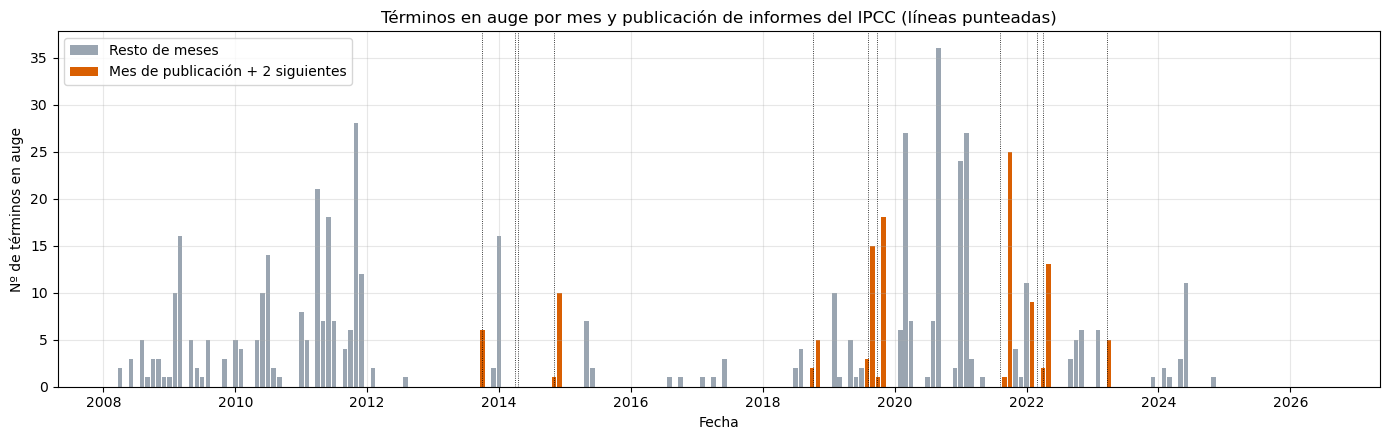

In [194]:
x = resultados_mes["terminos_en_auge"].values

resumen = pd.DataFrame({
    "meses": [post_ipcc.sum(), (~post_ipcc).sum()],
    "media": [x[post_ipcc].mean(), x[~post_ipcc].mean()],
    "mediana": [np.median(x[post_ipcc]), np.median(x[~post_ipcc])],
    "meses_con_algun_termino": [(x[post_ipcc] > 0).mean(), (x[~post_ipcc] > 0).mean()],
}, index=["post-IPCC", "resto"]).round(2)
display(resumen)

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(meses_eval.to_timestamp(), x, width=25, color="#9aa5b1", label="Resto de meses")
ax.bar(meses_eval.to_timestamp()[post_ipcc], x[post_ipcc], width=25, color="#d95f02",
       label=f"Mes de publicación + {K_MESES - 1} siguientes")
for f in eventos["fecha"]:
    ax.axvline(f, color="black", linewidth=0.6, linestyle=":")
ax.set_title("Términos en auge por mes y publicación de informes del IPCC (líneas punteadas)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nº de términos en auge")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/hipotesis_ipcc.png", dpi=300)
plt.show()

## 4.4. Contraste estadístico

Se compara la media de términos en auge entre los meses post-IPCC y el resto, con un test de **permutación por desplazamiento circular**:
- Se desplaza la marca de meses post-IPCC a todas las posiciones posibles de la serie y se calcula la diferencia en cada una.
- El p-valor es la fracción de desplazamientos con una diferencia igual o mayor que la observada (**unilateral**, porque la hipótesis dice "más").
- **Por qué no un test de permutación simple:** barajar los meses al azar supone que los meses son independientes, pero los términos en auge se agrupan en periodos de reescritura y los meses post-IPCC son contiguos. Barajando sin más, el p-valor sale demasiado pequeño (en una prueba salió ≈ 0,08 frente al valor de abajo). El desplazamiento circular conserva ese agrupamiento.

In [195]:
def diferencia(valores, marca):
    return valores[marca].mean() - valores[~marca].mean()


def p_desplazamiento(valores, marca):
    """p unilateral: fracción de desplazamientos circulares de la marca con una diferencia
    igual o mayor que la observada. Conserva el agrupamiento de los meses post-IPCC."""
    obs = diferencia(valores, marca)
    difs = np.array([diferencia(valores, np.roll(marca, s)) for s in range(len(marca))])
    return obs, (difs >= obs).mean()


obs, p = p_desplazamiento(x, post_ipcc)
print(f"Diferencia de medias (post-IPCC − resto): {obs:.2f} términos/mes")
print(f"p (unilateral, desplazamiento circular): {p:.3f}")

Diferencia de medias (post-IPCC − resto): 1.65 términos/mes
p (unilateral, desplazamiento circular): 0.183


## 4.5. Conclusión

**Con estos datos no se puede rechazar la hipótesis nula.** En los 28 meses post-IPCC hay más términos en auge que en el resto (media 4,14 frente a 2,49; mediana 1 frente a 0; el 54 % de los meses con algún término en auge, frente al 39 %). La diferencia de 1,65 términos por mes va en el sentido de la hipótesis, pero no es significativa (p = 0,183) y es compatible con el azar.

- **Poca potencia:** son 28 meses post-IPCC (11 informes, con ventanas que se solapan) y los términos en auge se concentran en pocos meses con 25-36 términos, así que unos pocos meses mandan sobre la media.
- **Fechas:** las de AR5 y SR1.5 no están verificadas, y SRREN y SREX (2011) se dejaron fuera, aunque 2011 es el año con más reescrituras.
- **Causalidad:** Wikipedia refleja ediciones de personas; una reescritura no implica que la causa sea un informe, ni se controlan otros eventos (acuerdos, conferencias del clima) que también podrían motivar cambios.

# 5. Entregables

Lista de lo que pide el enunciado:

- [x] Carpeta `data/processed/` con los datos limpios (`dataset_clean.parquet`, `textos_unicos.parquet`) y los indicadores (`volumen_*`, `sentimiento_*`, `topicos_*`, `palabras_clave_*`, `indicadores_mensual.csv`).
- [x] `data_cleaning.md`: transformaciones aplicadas (celda 1.9).
- [x] `motivation.md` con las cuatro partes pedidas: objetivo general, hipótesis, justificación del dataset y de los indicadores, y limitaciones o sesgos (celda de abajo).

Las figuras están en `figures/`. El texto de `motivation.md` recoge los resultados de esta ejecución; si se cambian parámetros o datos, conviene revisarlo.

In [196]:
MOTIVATION = """# Motivación del proyecto — Entrega 2

## 1. Objetivo general

Estudiar cómo evoluciona, entre 2008 y 2026, el texto de la entradilla del artículo de Wikipedia en inglés *Climate change* y cómo se relaciona con señales externas: la publicación de informes del IPCC y varias series climáticas, energéticas y mediáticas.

Se parte del dataset FAIR multimodal publicado en Hugging Face en la Entrega 1 (`miguel-mxrxra04/multimodal-climate-change-2008-2026`): una observación por semana con la entradilla vigente en esa fecha y series numéricas (CO2, Brent, anomalía de temperatura, CH4, N2O, índice ONI y volumen mediático de GDELT). Esta entrega prepara y limpia ese dataset y construye indicadores básicos (volumen, sentimiento, tópicos y palabras clave) que permiten formular y contrastar una hipótesis.

## 2. Preguntas de investigación e hipótesis

**Pregunta general.** ¿Cambia la entradilla de forma sistemática cuando ocurren eventos externos relevantes?

**Hipótesis (única).** En el mes de publicación de un informe del IPCC y en los dos siguientes, la entradilla incorpora más términos con un aumento súbito de frecuencia ("términos en auge") que en el resto de meses. La hipótesis nula es que no hay diferencia.

**Resultado.** No se rechaza la hipótesis nula. En los 28 meses post-IPCC hay más términos en auge que en el resto (media de 4,14 frente a 2,49; mediana de 1 frente a 0), pero la diferencia de 1,65 términos por mes no es significativa (p = 0,183 con un test de permutación por desplazamiento circular), así que los datos no permiten afirmar que los informes del IPCC provoquen más cambios en el texto.

**Otras observaciones.** Al quitar la tendencia (variaciones mes a mes), ni el sentimiento ni los tópicos ni el volumen de revisiones se relacionan con CO2, temperatura, ONI o Brent (|r| <= 0,20). En niveles aparecen correlaciones altas (p. ej. sentimiento frente a CO2, -0,68) que se deben a que las series comparten una tendencia a lo largo de los años, no a una relación real.

## 3. Justificación del dataset y de los indicadores

### Dataset

- Es **multimodal y temporal**: combina texto (la entradilla) con series numéricas alineadas por semana, lo que permite comparar cómo cambia el texto con señales externas.
- Conserva la **historia del texto**: una revisión de Wikipedia por semana, de 2008 a 2026 (978 observaciones, 376 textos distintos tras la limpieza).
- Procede de **fuentes públicas** (API de Wikipedia/MediaWiki, NOAA, NASA GISTEMP, Yahoo Finance y GDELT) y es reproducible.
- Solo contiene la **entradilla**, no el artículo completo; se mantuvo así por tamaño y por ser el resumen más estable del artículo, pero limita el análisis (ver apartado 4).

### Indicadores obligatorios

- **Volumen temporal.** El dataset guarda una sola revisión por semana, así que no sirve para contar publicaciones. Se descargó el historial completo de revisiones del artículo (13.469 revisiones) y se contó por semana y por mes. Mide la actividad editorial: media de 13,8 revisiones por semana, mediana de 7 y máximo de 152.
- **Sentimiento medio agregado.** El enunciado pide un modelo en español y los textos están en inglés, así que se tradujeron frase a frase (`Helsinki-NLP/opus-mt-en-es`) y se aplicó `pysentimiento/robertuito-sentiment-analysis`. Se eligió frente a BETO porque devuelve probabilidades graduadas, que se pueden promediar por mes. El tono es neutro o negativo (84 % de las semanas neutras, 16 % negativas, ninguna positiva) y se vuelve más negativo con los años (de -0,20 de media en 2008 a -0,42 en 2023).
- **Distribución de tópicos.** LDA (gensim) con 5 tópicos, entrenado sobre las frases únicas (cada texto es la media ponderada de sus frases), con coherencia c_v ≈ 0,44. Se eligió LDA y no BERTopic por el pequeño número de textos casi idénticos. Los tópicos cambian de foco con los años: emisiones y límites domina en 2012-2013 (0,60 y 0,54) y energía y combustibles fósiles sube hasta 0,37 en 2022.

### Indicador opcional

- **Palabras clave** (términos cuya frecuencia aumenta súbitamente). Se comparó la frecuencia de cada término en las 12 semanas siguientes y en las 12 anteriores, y se marcó como "en auge" si aparece al menos 3 veces por 1.000 palabras y su frecuencia se multiplica por 3 o más. Resultado: 594 de 1.011 términos; 393 aparecen por primera vez y 201 reaparecen. Los saltos se concentran en pocos periodos (2011 y 2019-2022), cuando la entradilla se reescribe, así que el indicador funciona como detector de reescrituras. Se eligió frente a la diversidad léxica (casi constante en textos de estilo parecido), la similitud semántica (repite lo que ya sabemos: el 62 % de las semanas repite el texto anterior) y la clasificación con LLM (coste y criterio subjetivo).

Con los cuatro indicadores y las series numéricas se construyó una tabla mensual (`data/processed/indicadores_mensual.csv`) que es la base de la hipótesis.

## 4. Limitaciones y posibles sesgos

**Datos**
- Un único artículo y solo su entradilla, en inglés: texto enciclopédico y neutro. No refleja la opinión pública ni la cobertura de los medios, y hereda el sesgo de la comunidad editora de Wikipedia en inglés.
- Mucha repetición: el 62 % de las semanas repite un texto ya visto (42 % antes de limpiar el formato). Las 978 semanas no son observaciones independientes; hay solo 376 textos distintos.
- Temperatura, CH4, N2O y ONI son series mensuales repetidas en las semanas de cada mes (cambian solo en el 22-23 % de las semanas). `media_volume_norm` (GDELT) es un proxy, casi siempre cercano a 0.
- La ficha de Hugging Face indica 977 registros y el dataset tiene 978.

**Indicadores**
- Sentimiento: traducción automática más un modelo entrenado con tuits. Mide el tono del contenido (riesgos, consecuencias), no una opinión, y casi no varía.
- Tópicos: pocas frases muy parecidas, con tópicos que comparten vocabulario (uno de ellos domina en solo 3 textos). Son orientativos; la proporción de cada tópico cambia con las versiones de la entradilla.
- Volumen: incluye ediciones de bots y reversiones, es del artículo completo y no solo de la entradilla, y tiene picos puntuales sin explicar.
- Palabras clave: cada término conserva un único salto, no se pueden evaluar las primeras y últimas 12 semanas y el resultado depende de los parámetros. Un salto indica cuándo cambia el texto, no por qué.

**Hipótesis**
- Solo 28 meses post-IPCC (11 informes, con ventanas que se solapan): poca potencia estadística.
- Las fechas de los informes AR5 y SR1.5 no están verificadas y se dejaron fuera los informes especiales de 2011 (SRREN y SREX), año con más reescrituras.
- Una asociación entre un informe y una reescritura no implica causalidad; otros eventos (acuerdos, conferencias del clima) o la propia dinámica de edición pueden explicarla.
"""

with open("motivation.md", "w", encoding="utf-8") as f:
    f.write(MOTIVATION)
print("Creado motivation.md")

Creado motivation.md
